Device: cuda; model: bert-base-uncased; max_lengths=[64, 128, 256]; train=1000; validation/test=500/500; batch_size=8; epochs=1


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (25 outputs left out)

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


max_length=256 | loss=0.5504 | val_acc=0.8180 val_f1=0.7838 | test_acc=0.8280 test_f1=0.8000 | train=44.9s | GPU_peak=2.50GB | CPU_RSS_peak=1.73GB

BẢNG KẾT QUẢ TEST — cùng mẫu train/validation/test
Max length | Accuracy | F1 | Training time (s) | GPU peak (GB) | CPU RSS peak (GB)
        64 | 0.7260 | 0.6667 | 16.0 | 2.06 | 1.66
       128 | 0.7160 | 0.6203 | 23.3 | 2.09 | 1.72
       256 | 0.8280 | 0.8000 | 44.9 | 2.50 | 1.73


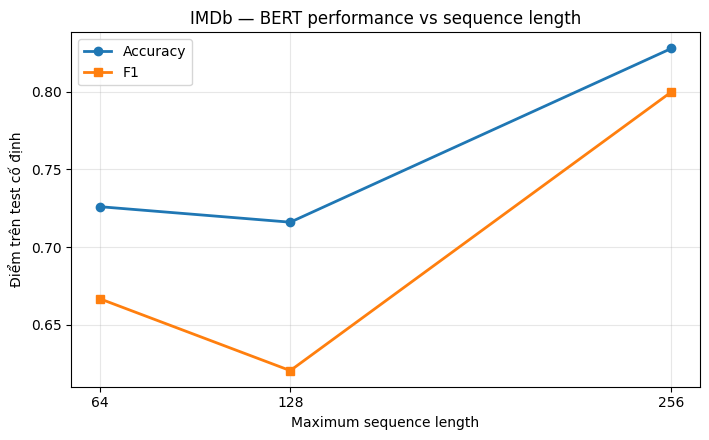

Thời gian train tăng theo max_length; attention có thành phần chi phí bậc hai theo độ dài T (O(T^2)). Hãy đối chiếu toàn bộ Accuracy/F1 trước khi quyết định có nên tăng độ dài.


In [ ]:
%pip -q install datasets scikit-learn matplotlib psutil

# Bài 17: Ảnh hưởng của maximum sequence length
import gc
import os
import random
import threading
import time
import numpy as np
import psutil
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification

SEED = 42
MODEL_NAME = "bert-base-uncased"
LENGTHS = [64, 128, 256]
TRAIN_SAMPLES = 1000
EVAL_PER_SPLIT = 500
BATCH_SIZE = 8
EPOCHS = 1
LEARNING_RATE = 2e-5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
print(f"Device: {DEVICE}; model: {MODEL_NAME}; max_lengths={LENGTHS}; train={TRAIN_SAMPLES}; validation/test={EVAL_PER_SPLIT}/{EVAL_PER_SPLIT}; batch_size={BATCH_SIZE}; epochs={EPOCHS}")
dataset = load_dataset("stanfordnlp/imdb")
train_full, official_test = dataset["train"], dataset["test"]
rng = np.random.default_rng(SEED)

# Lấy cùng 500 mẫu train mỗi nhãn; giữ nguyên danh sách này ở cả ba độ dài.
train_by_label = {0: [], 1: []}
for i, label in enumerate(train_full["label"]):
    train_by_label[int(label)].append(i)
train_ids = []
for label in (0, 1):
    train_ids.extend(rng.permutation(train_by_label[label])[:TRAIN_SAMPLES // 2].tolist())
rng.shuffle(train_ids)
train_raw = train_full.select(train_ids)

# Validation/test là hai tập cố định, tách biệt; mỗi tập cân bằng 250 mẫu mỗi nhãn.
test_by_label = {0: [], 1: []}
for i, label in enumerate(official_test["label"]):
    test_by_label[int(label)].append(i)
valid_ids, test_ids = [], []
for label in (0, 1):
    ids = rng.permutation(test_by_label[label])
    valid_ids.extend(ids[:EVAL_PER_SPLIT // 2].tolist())
    test_ids.extend(ids[EVAL_PER_SPLIT // 2:EVAL_PER_SPLIT].tolist())
valid_raw, test_raw = official_test.select(valid_ids), official_test.select(test_ids)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
process = psutil.Process(os.getpid())

def prepare_loader(raw, max_length, batch_size, shuffle=False, seed=SEED):
    def encode(batch):
        return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=max_length)
    encoded = raw.map(encode, batched=True, remove_columns=["text"])
    encoded.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(encoded, batch_size=batch_size, shuffle=shuffle, generator=generator)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    truths, predictions = [], []
    for batch in loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        logits = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
        predictions.extend(logits.argmax(dim=1).cpu().tolist())
        truths.extend(batch["label"].cpu().tolist())
    return accuracy_score(truths, predictions), f1_score(truths, predictions, zero_division=0)

results = []
for max_length in LENGTHS:
    train_loader = prepare_loader(train_raw, max_length, BATCH_SIZE, shuffle=True, seed=SEED)
    valid_loader = prepare_loader(valid_raw, max_length, BATCH_SIZE * 2)
    test_loader = prepare_loader(test_raw, max_length, BATCH_SIZE * 2)
    seed_everything(SEED)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    peak_cpu_bytes = [process.memory_info().rss]
    stop_sampling = threading.Event()
    def sample_cpu_memory():
        while not stop_sampling.is_set():
            peak_cpu_bytes[0] = max(peak_cpu_bytes[0], process.memory_info().rss)
            stop_sampling.wait(0.2)
    sampler = threading.Thread(target=sample_cpu_memory, daemon=True)
    sampler.start()

    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
    model.train()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()
    for epoch in range(EPOCHS):
        total_loss = 0.0
        for batch in train_loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            outputs = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"], labels=batch["label"])
            outputs.loss.backward()
            optimizer.step()
            total_loss += outputs.loss.item()
            peak_cpu_bytes[0] = max(peak_cpu_bytes[0], process.memory_info().rss)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    train_seconds = time.perf_counter() - start
    val_acc, val_f1 = evaluate(model, valid_loader)
    test_acc, test_f1 = evaluate(model, test_loader)
    if torch.cuda.is_available():
        gpu_peak_gb = torch.cuda.max_memory_allocated() / (1024 ** 3)
    else:
        gpu_peak_gb = 0.0
    peak_cpu_bytes[0] = max(peak_cpu_bytes[0], process.memory_info().rss)
    stop_sampling.set()
    sampler.join()
    cpu_peak_gb = peak_cpu_bytes[0] / (1024 ** 3)
    row = {"max_length": max_length, "loss": total_loss / len(train_loader),
           "val_accuracy": val_acc, "val_f1": val_f1, "accuracy": test_acc,
           "f1": test_f1, "training_time_s": train_seconds,
           "gpu_peak_gb": gpu_peak_gb, "cpu_peak_gb": cpu_peak_gb}
    results.append(row)
    print(f"max_length={max_length:>3} | loss={row['loss']:.4f} | val_acc={val_acc:.4f} val_f1={val_f1:.4f} | test_acc={test_acc:.4f} test_f1={test_f1:.4f} | train={train_seconds:.1f}s | GPU_peak={gpu_peak_gb:.2f}GB | CPU_RSS_peak={cpu_peak_gb:.2f}GB")
    del model, optimizer, train_loader, valid_loader, test_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nBẢNG KẾT QUẢ TEST — cùng mẫu train/validation/test")
print("Max length | Accuracy | F1 | Training time (s) | GPU peak (GB) | CPU RSS peak (GB)")
for r in results:
    print(f"{r['max_length']:>10} | {r['accuracy']:.4f} | {r['f1']:.4f} | {r['training_time_s']:.1f} | {r['gpu_peak_gb']:.2f} | {r['cpu_peak_gb']:.2f}")

# Learning/sequence-length curve. Matplotlib keeps distinct colors for the two metrics.
plt.figure(figsize=(7.2, 4.5))
plt.plot(LENGTHS, [r["accuracy"] for r in results], marker="o", linewidth=2, label="Accuracy")
plt.plot(LENGTHS, [r["f1"] for r in results], marker="s", linewidth=2, label="F1")
plt.xticks(LENGTHS)
plt.xlabel("Maximum sequence length")
plt.ylabel("Điểm trên test cố định")
plt.title("IMDb — BERT performance vs sequence length")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
print("Thời gian train tăng theo max_length; attention có thành phần chi phí bậc hai theo độ dài T (O(T^2)). Hãy đối chiếu toàn bộ Accuracy/F1 trước khi quyết định có nên tăng độ dài.")
